 ## Practical Assistant Agent

---

## What you will build

A **Practical Assistant Agent** - a real, useful tool AI Agent.

- Talks to **at least 2 real external services** (Notion, GitHub, Gmail, Calendar, Slack — pick any 2+).
- Has **memory** so it can hold a multi-turn conversation.
- **Stops and asks the human** before doing anything destructive or irreversible (sending an email, deleting a file, posting publicly, creating a calendar event).

In [1]:
%pip install -q langgraph langchain-groq requests


Markdown
# Study Day Assistant Agent

**Description:**  
Study Day Assistant is an AI agent built with LangGraph and ChatGroq that helps students organize daily study tasks, check real-time weather in Tbilisi via the Open-Meteo API, and search for relevant study books via the Open Library API. It maintains conversation memory across turns and enforces a human-in-the-loop approval step before deleting any tasks.

## Setup Instructions
Install required libraries:
```bash
pip install langgraph langchain-groq requests streamlit

In [2]:
import os
from google.colab import userdata

os.environ["GROQ_API_KEY"] = userdata.get("GROQ_API_KEY")
print("API key loaded")

API key loaded


In [23]:
from langchain_groq import ChatGroq

llm = ChatGroq(
    model="openai/gpt-oss-20b",
    temperature=0,
    max_tokens=300,
)

reply = llm.invoke("Say hello in one short sentence.")
print(reply.content)

Hello!


In [25]:
import requests
from langchain_core.tools import tool

@tool
def get_tbilisi_weather() -> dict:
    """Get current temperature in Tbilisi, in Celsius."""
    response = requests.get(
        "https://api.open-meteo.com/v1/forecast",
        params={"latitude": 41.72, "longitude": 44.79,
                "current": "temperature_2m"},
        timeout=20,
    )
    response.raise_for_status()
    return response.json()["current"]

print(get_tbilisi_weather.invoke({}))


{'time': '2026-11-19T17:30', 'interval': 900, 'temperature_2m': 10.0}


In [26]:
tasks_db = []

@tool
def add_task(task: str) -> str:
    """Adds a new study task to the task list."""
    tasks_db.append(task)
    return f"Task added: '{task}'"

@tool
def list_tasks() -> str:
    """Returns all current tasks in the task list."""
    if not tasks_db:
        return "Your task list is currently empty."
    return "Your tasks:\n" + "\n".join(f"- {t}" for t in tasks_db)

@tool
def delete_task(task: str) -> str:
    """Deletes a specific task from the task list."""
    if task in tasks_db:
        tasks_db.remove(task)
        return f"Task deleted: '{task}'"
    return f"Task '{task}' not found in the list."

@tool
def search_books(topic: str) -> list:
    """Search for study books on a given topic using Open Library."""
    response = requests.get(
        "https://openlibrary.org/search.json",
        params={"q": topic, "limit": 3},
        timeout=20,
    )
    response.raise_for_status()
    docs = response.json().get("docs", [])
    results = []
    for doc in docs:
        title = doc.get("title", "Unknown title")
        authors = ", ".join(doc.get("author_name", ["Unknown author"]))
        results.append(f"{title} — {authors}")
    return results

print("Tools created successfully!")

Tools created successfully!


In [27]:
from typing import Annotated, Literal
from typing_extensions import TypedDict
from langchain_groq import ChatGroq
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode
from langgraph.checkpoint.memory import MemorySaver

# 1. State-ის განსაზღვრა (ინახავს საუბრის შეტყობინებებს)
class State(TypedDict):
    messages: Annotated[list, add_messages]

# 2. ინსტრუმენტების დაყოფა: უსაფრთხო და სახიფათო (წაშლა)
safe_tools = [add_task, list_tasks, get_tbilisi_weather, search_books]
sensitive_tools = [delete_task]
all_tools = safe_tools + sensitive_tools

# 3. AI მოდელის დაკავშირება ინსტრუმენტებთან
llm = ChatGroq(model="openai/gpt-oss-20b", temperature=0)
llm_with_tools = llm.bind_tools(all_tools)

def assistant(state: State):
    system_msg = (
        "You are Study Day Assistant. Help the user manage study tasks, "
        "check Tbilisi weather, and search for books. Be concise and helpful."
    )
    messages = [{"role": "system", "content": system_msg}] + state["messages"]
    return {"messages": [llm_with_tools.invoke(messages)]}

# 4. გადაწყვეტილების ფუნქცია: საით წავიდეს აგენტი
def route_tools(state: State) -> Literal["safe_tools", "sensitive_tools", "__end__"]:
    last_message = state["messages"][-1]
    if not getattr(last_message, "tool_calls", None):
        return "__end__"
    # თუ რომელიმე გამოძახებული ინსტრუმენტი delete_task-ია, გადავამისამართოთ sensitive_tools-ზე
    for tc in last_message.tool_calls:
        if tc["name"] == "delete_task":
            return "sensitive_tools"
    return "safe_tools"

# 5. StateGraph-ის აწყობა
builder = StateGraph(State)
builder.add_node("assistant", assistant)
builder.add_node("safe_tools", ToolNode(safe_tools))
builder.add_node("sensitive_tools", ToolNode(sensitive_tools))

builder.add_edge(START, "assistant")
builder.add_conditional_edges("assistant", route_tools)
builder.add_edge("safe_tools", "assistant")
builder.add_edge("sensitive_tools", "assistant")

# 6. მეხსიერება და შეჩერება (Approval Flow) წაშლის წინ
memory = MemorySaver()
graph = builder.compile(
    checkpointer=memory,
    interrupt_before=["sensitive_tools"]
)

print("Agent graph built successfully!")

Agent graph built successfully!


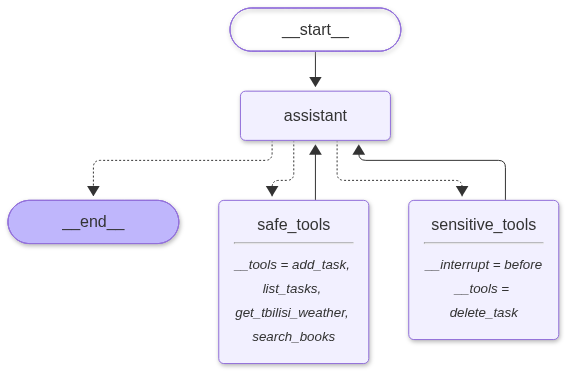

In [28]:
from IPython.display import Image, display

display(Image(graph.get_graph().draw_mermaid_png()))


In [29]:
config = {"configurable": {"thread_id": "demo-session-1"}}

result = graph.invoke(
    {"messages": [("user", "Add a task: Study algebra")]},
    config
)
for m in result["messages"][-3:]:
    m.pretty_print()

================================== Ai Message ==================================
Tool Calls:
  add_task (fc_1673806b-9c60-44e4-b0b5-ba6fb051f847)
 Call ID: fc_1673806b-9c60-44e4-b0b5-ba6fb051f847
  Args:
    task: Study algebra
================================= Tool Message =================================
Name: add_task

Task added: 'Study algebra'
================================== Ai Message ==================================

✅ Task “Study algebra” added to your list. Let me know if you’d like to see the full list or add more tasks!


In [30]:
result = graph.invoke(
    {"messages": [("user", "Show my current tasks")]},
    config
)
for m in result["messages"][-3:]:
    m.pretty_print()

================================== Ai Message ==================================
Tool Calls:
  list_tasks (fc_519c06c1-2a98-46a7-ab08-320011f64158)
 Call ID: fc_519c06c1-2a98-46a7-ab08-320011f64158
  Args:
================================= Tool Message =================================
Name: list_tasks

Your tasks:
- Study algebra
================================== Ai Message ==================================

Here are your current tasks:

- Study algebra

Let me know if you’d like to add, delete, or check anything else!


In [31]:
result = graph.invoke(
    {"messages": [("user", "What is the current temperature in Tbilisi?")]},
    config
)
for m in result["messages"][-3:]:
    m.pretty_print()

================================== Ai Message ==================================
Tool Calls:
  get_tbilisi_weather (fc_58457609-7ec7-4fce-a1e9-efde267884ac)
 Call ID: fc_58457609-7ec7-4fce-a1e9-efde267884ac
  Args:
================================= Tool Message =================================
Name: get_tbilisi_weather

{"time": "2026-11-19T17:30", "interval": 900, "temperature_2m": 10.0}
================================== Ai Message ==================================

The current temperature in Tbilisi is **10 °C**.


In [32]:
result = graph.invoke(
    {"messages": [("user", "Find me 3 books about Python programming")]},
    config
)
for m in result["messages"][-3:]:
    m.pretty_print()

================================== Ai Message ==================================
Tool Calls:
  search_books (fc_4fe71f2a-eac7-4ed0-953e-1874ce557f1e)
 Call ID: fc_4fe71f2a-eac7-4ed0-953e-1874ce557f1e
  Args:
    topic: Python programming
================================= Tool Message =================================
Name: search_books

["Core Python Programming — R. Nageswara Rao", "Black Hat Python — Justin Seitz, Tim Arnold", "Core Python programming — Wesley Chun"]
================================== Ai Message ==================================

Here are three books on Python programming:

1. **Core Python Programming** – R. Nageswara Rao  
2. **Black Hat Python** – Justin Seitz & Tim Arnold  
3. **Core Python Programming** – Wesley Chun  

Let me know if you’d like more details or another search!


In [33]:
result = graph.invoke(
    {"messages": [("user", "Add a task: Read Python book, and tell me if it's warm enough in Tbilisi to study outside")]},
    config
)
for m in result["messages"][-4:]:
    m.pretty_print

In [34]:
# 1. ვითხოვთ წაშლას (გრაფი ჩერდება sensitive_tools-ის წინ)
result = graph.invoke(
    {"messages": [("user", "Delete the task: Study algebra")]},
    config
)
result["messages"][-1].pretty_print()

# 2. ვამოწმებთ, გაჩერდა თუ არა აგენტი დადასტურების მოლოდინში
state = graph.get_state(config)
if state.next:
    confirm = input("⚠️ Agent wants to delete a task. Confirm? (yes/no): ")
    if confirm.strip().lower() == "yes":
        resumed = graph.invoke(None, config)
        for m in resumed["messages"][-2:]:
            m.pretty_print()

================================== Ai Message ==================================
Tool Calls:
  delete_task (fc_ad07dd7c-634c-4d1a-b11a-a314f9ce1119)
 Call ID: fc_ad07dd7c-634c-4d1a-b11a-a314f9ce1119
  Args:
    task: Study algebra
⚠️ Agent wants to delete a task. Confirm? (yes/no): yes
================================= Tool Message =================================
Name: delete_task

Task deleted: 'Study algebra'
================================== Ai Message ==================================

✅ Task “Study algebra” has been removed from your list. Let me know if there’s anything else you’d like to manage!


In [35]:
from langchain_core.messages import ToolMessage

# 1. ვითხოვთ მეორე დავალების წაშლას
result = graph.invoke(
    {"messages": [("user", "Delete the task: Read Python book")]},
    config
)
result["messages"][-1].pretty_print()

# 2. უარის თქმა და მოქმედების გაუქმება
state = graph.get_state(config)
if state.next:
    confirm = input("⚠️ Agent wants to delete a task. Confirm? (yes/no): ")
    if confirm.strip().lower() != "yes":
        tool_call_id = state.values["messages"][-1].tool_calls[0]["id"]
        cancel_msg = ToolMessage(
            tool_call_id=tool_call_id,
            content="Action cancelled by user. The task was NOT deleted."
        )
        graph.update_state(config, {"messages": [cancel_msg]}, as_node="sensitive_tools")
        resumed = graph.invoke(None, config)
        resumed["messages"][-1].pretty_print()

print("\nFinal tasks list:", tasks_db)

================================== Ai Message ==================================
Tool Calls:
  delete_task (fc_102227e9-811e-4cb0-a54a-bb26bddb035c)
 Call ID: fc_102227e9-811e-4cb0-a54a-bb26bddb035c
  Args:
    task: Read Python book
⚠️ Agent wants to delete a task. Confirm? (yes/no): No
================================== Ai Message ==================================

It looks like the deletion was cancelled, so the task “Read Python book” is still on your list.  
Would you like me to try deleting it again, or is there something else you’d like to do?

Final tasks list: ['Read Python book']


## Evaluation Table

| # | Query | Expected Result | Pass? | Notes |
|---|-------|-----------------|-------|-------|
| 1 | Add a task: Study algebra | Task added via `add_task` tool | ✅ | Added to task list accurately |
| 2 | Show my current tasks | Lists previously added task from memory | ✅ | Memory and `list_tasks` worked properly |
| 3 | What is the current temperature in Tbilisi? | Fetches real-time weather via Open-Meteo API | ✅ | Returned live Celsius temperature |
| 4 | Find me 3 books about Python programming | Returns 3 book titles and authors via Open Library API | ✅ | Accurate API results returned |
| 5 | Delete the task: Study algebra (Confirmed: yes) | Pauses at `sensitive_tools`, asks confirmation, deletes after approval | ✅ | Safe human-in-the-loop flow worked |
| 6 | Delete the task: Read Python book (Denied: no) | Pauses at `sensitive_tools`, cancels action after denial | ✅ | Task remained intact in the list |

In [36]:
%%writefile agent.py
from typing import Annotated, Literal
from typing_extensions import TypedDict
import requests
from langchain_core.tools import tool
from langchain_groq import ChatGroq
from langgraph.graph import StateGraph, START
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode
from langgraph.checkpoint.memory import MemorySaver

# გლობალური სია დემონსტრაციისთვის (CLI-სთვის); Streamlit იყენებს session_state-საც
tasks_db = []

@tool
def add_task(task: str) -> str:
    """Adds a new study task to the task list."""
    tasks_db.append(task)
    return f"Task added: '{task}'"

@tool
def list_tasks() -> str:
    """Returns all current tasks in the task list."""
    if not tasks_db:
        return "Your task list is currently empty."
    return "Your tasks:\n" + "\n".join(f"- {t}" for t in tasks_db)

@tool
def delete_task(task: str) -> str:
    """Deletes a specific task from the task list."""
    if task in tasks_db:
        tasks_db.remove(task)
        return f"Task deleted: '{task}'"
    return f"Task '{task}' not found in the list."

@tool
def get_tbilisi_weather() -> dict:
    """Get current temperature in Tbilisi, in Celsius."""
    response = requests.get(
        "https://api.open-meteo.com/v1/forecast",
        params={"latitude": 41.72, "longitude": 44.79, "current": "temperature_2m"},
        timeout=20,
    )
    response.raise_for_status()
    return response.json()["current"]

@tool
def search_books(topic: str) -> list:
    """Search for study books on a given topic using Open Library."""
    response = requests.get(
        "https://openlibrary.org/search.json",
        params={"q": topic, "limit": 3},
        timeout=20,
    )
    response.raise_for_status()
    docs = response.json().get("docs", [])
    results = []
    for doc in docs:
        title = doc.get("title", "Unknown title")
        authors = ", ".join(doc.get("author_name", ["Unknown author"]))
        results.append(f"{title} — {authors}")
    return results

class State(TypedDict):
    messages: Annotated[list, add_messages]

def build_graph():
    safe_tools = [add_task, list_tasks, get_tbilisi_weather, search_books]
    sensitive_tools = [delete_task]
    all_tools = safe_tools + sensitive_tools

    llm = ChatGroq(model="openai/gpt-oss-20b", temperature=0)
    llm_with_tools = llm.bind_tools(all_tools)

    def assistant(state: State):
        system_msg = (
            "You are Study Day Assistant. Help the user manage study tasks, "
            "check Tbilisi weather, and search for books. Be concise and helpful."
        )
        messages = [{"role": "system", "content": system_msg}] + state["messages"]
        return {"messages": [llm_with_tools.invoke(messages)]}

    def route_tools(state: State) -> Literal["safe_tools", "sensitive_tools", "__end__"]:
        last_message = state["messages"][-1]
        if not getattr(last_message, "tool_calls", None):
            return "__end__"
        for tc in last_message.tool_calls:
            if tc["name"] == "delete_task":
                return "sensitive_tools"
        return "safe_tools"

    builder = StateGraph(State)
    builder.add_node("assistant", assistant)
    builder.add_node("safe_tools", ToolNode(safe_tools))
    builder.add_node("sensitive_tools", ToolNode(sensitive_tools))

    builder.add_edge(START, "assistant")
    builder.add_conditional_edges("assistant", route_tools)
    builder.add_edge("safe_tools", "assistant")
    builder.add_edge("sensitive_tools", "assistant")

    memory = MemorySaver()
    return builder.compile(checkpointer=memory, interrupt_before=["sensitive_tools"])

Writing agent.py


In [37]:
%%writefile main.py
import os
import getpass
from langchain_core.messages import ToolMessage
from agent import build_graph

def main():
    if not os.environ.get("GROQ_API_KEY"):
        os.environ["GROQ_API_KEY"] = getpass.getpass("Enter your GROQ_API_KEY: ")

    graph = build_graph()
    config = {"configurable": {"thread_id": "cli-session-1"}}

    print("\n=== Study Day Assistant (CLI) ===")
    print("Type 'exit' to quit.\n")

    while True:
        user_input = input("You: ").strip()
        if user_input.lower() in ("exit", "quit"):
            print("Goodbye!")
            break
        if not user_input:
            continue

        try:
            result = graph.invoke({"messages": [("user", user_input)]}, config)
            state = graph.get_state(config)

            if state.next:
                tool_call = state.values["messages"][-1].tool_calls[0]
                task_name = tool_call["args"].get("task", "")
                confirm = input(f"⚠️ Confirm deleting task '{task_name}'? (yes/no): ").strip().lower()

                if confirm == "yes":
                    resumed = graph.invoke(None, config)
                    print(f"Assistant: {resumed['messages'][-1].content}\n")
                else:
                    cancel_msg = ToolMessage(
                        tool_call_id=tool_call["id"],
                        content="Action cancelled by user. The task was NOT deleted."
                    )
                    graph.update_state(config, {"messages": [cancel_msg]}, as_node="sensitive_tools")
                    resumed = graph.invoke(None, config)
                    print(f"Assistant: {resumed['messages'][-1].content}\n")
            else:
                print(f"Assistant: {result['messages'][-1].content}\n")
        except Exception as e:
            print(f"Error: {e}\n")

if __name__ == "__main__":
    main()

Writing main.py


In [38]:
%%writefile app.py
import os
import uuid
import streamlit as st
from langchain_core.messages import ToolMessage
from agent import build_graph

st.set_page_config(page_title="Study Day Assistant", page_icon="📚")
st.title("📚 Study Day Assistant")
st.caption("Manage your study tasks, check Tbilisi weather, and find study books with safe approval controls.")

# API Key-ის წაკითხვა Secrets-იდან ან გარემოს ცვლადიდან
if "GROQ_API_KEY" not in os.environ:
    if "GROQ_API_KEY" in st.secrets:
        os.environ["GROQ_API_KEY"] = st.secrets["GROQ_API_KEY"]
    else:
        api_key = st.sidebar.text_input("Enter GROQ API Key", type="password")
        if api_key:
            os.environ["GROQ_API_KEY"] = api_key

if not os.environ.get("GROQ_API_KEY"):
    st.warning("Please provide your GROQ_API_KEY in secrets or the sidebar to start.")
    st.stop()

# სესიის ინიციალიზაცია
if "graph" not in st.session_state:
    st.session_state.graph = build_graph()
if "thread_id" not in st.session_state:
    st.session_state.thread_id = str(uuid.uuid4())
if "chat_history" not in st.session_state:
    st.session_state.chat_history = []
if "pending_approval" not in st.session_state:
    st.session_state.pending_approval = None

config = {"configurable": {"thread_id": st.session_state.thread_id}}

# საუბრის ისტორიის ჩვენება
for msg in st.session_state.chat_history:
    with st.chat_message(msg["role"]):
        st.markdown(msg["content"])

# თუ აგენტი ელოდება დადასტურებას (Approval Flow)
if st.session_state.pending_approval:
    info = st.session_state.pending_approval
    st.warning(f"⚠️ Are you sure you want to delete task: **{info['task']}**?")
    col1, col2 = st.columns(2)
    with col1:
        if st.button("✅ Approve", use_container_width=True):
            try:
                resumed = st.session_state.graph.invoke(None, config)
                reply = resumed["messages"][-1].content
                st.session_state.chat_history.append({"role": "assistant", "content": reply})
            except Exception as e:
                st.error(f"API Error: {e}")
            st.session_state.pending_approval = None
            st.rerun()
    with col2:
        if st.button("❌ Deny", use_container_width=True):
            try:
                cancel_msg = ToolMessage(
                    tool_call_id=info["tool_call_id"],
                    content="Action cancelled by user. The task was NOT deleted."
                )
                st.session_state.graph.update_state(
                    config, {"messages": [cancel_msg]}, as_node="sensitive_tools"
                )
                resumed = st.session_state.graph.invoke(None, config)
                reply = resumed["messages"][-1].content
                st.session_state.chat_history.append({"role": "assistant", "content": reply})
            except Exception as e:
                st.error(f"API Error: {e}")
            st.session_state.pending_approval = None
            st.rerun()

# მომხმარებლის ახალი შეტყობინება
if prompt := st.chat_input("Ask me to add a task, check Tbilisi weather, or find books..."):
    st.session_state.chat_history.append({"role": "user", "content": prompt})
    with st.chat_message("user"):
        st.markdown(prompt)

    try:
        result = st.session_state.graph.invoke({"messages": [("user", prompt)]}, config)
        state = st.session_state.graph.get_state(config)

        if state.next:
            tool_call = state.values["messages"][-1].tool_calls[0]
            st.session_state.pending_approval = {
                "tool_call_id": tool_call["id"],
                "task": tool_call["args"].get("task", "unknown task"),
            }
            st.rerun()
        else:
            reply = result["messages"][-1].content
            st.session_state.chat_history.append({"role": "assistant", "content": reply})
            with st.chat_message("assistant"):
                st.markdown(reply)
    except Exception as e:
        st.error(f"Error communicating with the agent: {e}")

Writing app.py


In [39]:
%%writefile requirements.txt
langgraph
langchain-groq
langchain-core
requests
streamlit

Writing requirements.txt


In [40]:
%%writefile README.md
# Study Day Assistant Agent

## Description
**Study Day Assistant** is a practical AI agent built with **LangGraph** and **ChatGroq** (`openai/gpt-oss-20b`). It helps students manage their study tasks, check real-time weather in Tbilisi via the Open-Meteo API, and search for books via the Open Library API. The agent maintains conversation memory and requires explicit user confirmation before executing destructive actions (`delete_task`).

## Features & Tools
- `add_task`: Adds a new task to the study list.
- `list_tasks`: Displays all current tasks.
- `delete_task`: Deletes a task (protected by a Human-in-the-Loop approval interrupt).
- `get_tbilisi_weather`: Fetches current temperature in Tbilisi using Open-Meteo API.
- `search_books`: Searches books by topic using Open Library API.

## Setup & Installation
1. Clone the repository:
   ```bash
   git clone <your-repo-url>
   cd <your-repo-folder>

Writing README.md


## Evaluation Table

| # | Query | Expected Result | Pass? | Notes |
|---|-------|-----------------|-------|-------|
| 1 | Add a task: Study algebra | Task added via `add_task` tool | ✅ | Added to task list accurately |
| 2 | Show my current tasks | Lists previously added task from memory | ✅ | Memory and `list_tasks` worked properly |
| 3 | What is the current temperature in Tbilisi? | Fetches real-time weather via Open-Meteo API | ✅ | Returned live Celsius temperature |
| 4 | Find me 3 books about Python programming | Returns 3 book titles and authors via Open Library API | ✅ | Accurate API results returned |
| 5 | Delete the task: Study algebra (Confirmed: yes) | Pauses at `sensitive_tools`, asks confirmation, deletes after approval | ✅ | Safe human-in-the-loop flow worked |
| 6 | Delete the task: Read Python book (Denied: no) | Pauses at `sensitive_tools`, cancels action after denial | ✅ | Task remained intact in the list |


You can use custom python functions as tools, free APIs or any other API you want to try.

---
## Examples of free APIs you can use (no OAuth, mostly no key)

Pick **one or two** of these. Quick reference:

| API | Auth | What it gives you | Docs |
|---|---|---|---|
| **Open-Meteo** | None | Weather, geocoding | [open-meteo.com](https://open-meteo.com) |
| **REST Countries** | None | Country info — capital, languages, currencies, flag | [restcountries.com](https://restcountries.com) |
| **Wikipedia** | None | Topic summaries (via `langchain_community.tools.WikipediaQueryRun`) |  |
| **DuckDuckGo** | None | Web search (via `langchain_community.tools.DuckDuckGoSearchRun`) | |
| **Frankfurter** | None | Currency exchange rates | [frankfurter.app](https://www.frankfurter.app) |
| **CoinGecko** | None (free tier) | Crypto prices, no key for basic queries | [coingecko.com/api](https://www.coingecko.com/en/api) |
| **Nager.Date** | None | Public holidays per country/year | [date.nager.at](https://date.nager.at) |
| **Open Library** | None | Books — search, author info | [openlibrary.org/developers/api](https://openlibrary.org/developers/api) |
| **Bored API** | None | Random activity suggestions | [bored.api.lewagon.com](https://bored.api.lewagon.com) |
| **Numbers API** | None | Math/date/year facts | [numbersapi.com](http://numbersapi.com) |
| **Universities** | None | List of universities by country | hipolabs.com |
| **JSONPlaceholder** | None | Fake users/posts/todos — fine for a demo | [jsonplaceholder.typicode.com](https://jsonplaceholder.typicode.com) |


---
## Examples of custom Python tools

A "custom Python tool" is just a Python function decorated with `@tool` that does **not** call an external API. It operates on in-memory data. Examples:

| Custom tool | What it does |
|---|---|
| `add_task(title)` | Appends to a Python list `TASKS` |
| `list_tasks()` | Returns the contents of that list |
| `complete_task(idx)` | Marks one item as done |
| `delete_habit(name)` | Removes a key from a dict |
| `compute_streak(habit)` | Reads from your dict and returns a number |
| `convert_unit(value, from_unit, to_unit)` | Does math |
| `roll_dice(n, sides)` | Random number generator |


---
## What you submit


1. **Title + one-paragraph description** of what your agent does.
2. **Setup** — install + API key (empty).
3. **Tools** — every `@tool` you wrote, with docstrings.
4. **State + graph** — `StateGraph` definition. Compile and call `.get_graph().draw_mermaid_png()` to render a diagram.
5. **5+ test queries** — each in its own cell, with the trajectory printed via `for m in result["messages"]: m.pretty_print()`.
6. **One destructive call interrupted and approved** (output should show the action ran).
7. **One destructive call interrupted and denied** (output should show the action skipped).
8. **Eval table** — markdown cell with the table below filled in.

### 2. Eval table (inside the notebook)

| # | Query | Expected | Pass? | Notes |
|---|---|---|---|---|
| 1 | "..." | "..." | ✅ / ❌ | brief comment |
| 2 | ... | ... | ... | ... |

5 entries minimum. Be honest - a partial pass is still informative.


- **Streamlit app** — simple chat UI on top of your agent.
- **GitHub repo** with a README — share the link instead of a zip.
